In [1]:
setwd("E:/MB_Bulk_RNA_seq/Post_Analysis_script")

meta_all = read.csv("./Bulk_MB_Analysis/meta_all_ICGC_st_Jude.csv")


In [2]:
SHH_Alt = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/SHH_Alt.csv",row.names = 'X')
G4_Alt = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/G4_Alt.csv",row.names = 'X')
G3_Alt = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/G3_Alt.csv",row.names = 'X')
WNT_Alt = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/WNT_Alt.csv",row.names = 'X')
SHH_Ref = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/SHH_Ref.csv",row.names = 'X')
G4_Ref = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/G4_Ref.csv",row.names = 'X')
G3_Ref = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/G3_Ref.csv",row.names = 'X')
WNT_Ref = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Bulk_MB_Analysis_Data/WNT_Ref.csv",row.names = 'X')

filter = read.csv("E:/MB_Bulk_RNA_seq/retest_paired_end correction/False_positive_filter/Final_Alt_filtered_depth_Alt_freq.csv",row.names = 'X')

SHH_Ref = SHH_Ref[intersect(rownames(SHH_Ref),rownames(filter)),]
SHH_Alt= SHH_Alt[intersect(rownames(SHH_Alt),rownames(filter)),]

G3_Ref = G3_Ref[intersect(rownames(G3_Ref),rownames(filter)),]
G3_Alt= G3_Alt[intersect(rownames(G3_Alt),rownames(filter)),]

G4_Ref = G4_Ref[intersect(rownames(G4_Ref),rownames(filter)),]
G4_Alt= G4_Alt[intersect(rownames(G4_Alt),rownames(filter)),]

WNT_Ref = WNT_Ref[intersect(rownames(WNT_Ref),rownames(filter)),]
WNT_Alt= WNT_Alt[intersect(rownames(WNT_Alt),rownames(filter)),]
Xenografts_G <- paste0(
  c("SJMB062378_X1", "SJMB062376_X1", "SJMB055853_X2", 
    "SJMB062375_X1", "SJMB049291_X2", "SJMB044814_X3"),
  ".RNA.Seq_1.fq.gz_Alt"
)
Xenografts_A <- paste0(
  c("SJMB062378_X1", "SJMB062376_X1", "SJMB055853_X2", 
    "SJMB062375_X1", "SJMB049291_X2", "SJMB044814_X3"),
  ".RNA.Seq_1.fq.gz_Ref"
)
G3_Ref = G3_Ref[,!colnames(G3_Ref) %in% Xenografts_A]
G4_Ref = G4_Ref[,!colnames(G4_Ref) %in% Xenografts_A]
WNT_Ref = WNT_Ref[,!colnames(WNT_Ref) %in% Xenografts_A]
SHH_Ref = SHH_Ref[,!colnames(SHH_Ref) %in% Xenografts_A]


G3_Alt = G3_Alt[,!colnames(G3_Alt) %in% Xenografts_G]
G4_Alt = G4_Alt[,!colnames(G4_Alt) %in% Xenografts_G]
WNT_Alt = WNT_Alt[,!colnames(WNT_Alt) %in% Xenografts_G]
SHH_Alt = SHH_Alt[,!colnames(SHH_Alt) %in% Xenografts_G]


###############################################################################33


In [3]:
# Printing dimensions (shape) of dataframes
# In R, 'dim()' returns the dimensions (rows, columns) of a data frame.
# We can iterate through a list of data frames and their names.
dataframe_names <- c("SHH_Alt", "G4_Alt", "G3_Alt", "WNT_Alt")
dataframes_to_check <- list(SHH_Alt, G4_Alt, G3_Alt, WNT_Alt)

for (i in seq_along(dataframe_names)) {
  name <- dataframe_names[i]
  df <- dataframes_to_check[[i]]
  cat(sprintf("%s shape: %s\n", name, paste(dim(df), collapse = " ")))
}

# Assigning column names from one data frame to another
# In R, 'colnames()' is used to get or set column names.
colnames(SHH_Ref) <- colnames(SHH_Alt)
colnames(G3_Ref) <- colnames(G3_Alt)
colnames(G4_Ref) <- colnames(G4_Alt)
colnames(WNT_Ref) <- colnames(WNT_Alt)

# Performing element-wise division for frequency calculation
# R performs element-wise operations directly on data frames or matrices
# if their dimensions are compatible.
SHH_freq <- SHH_Alt / (SHH_Alt + SHH_Ref)
G3_freq <- G3_Alt / (G3_Alt + G3_Ref)
G4_freq <- G4_Alt / (G4_Alt + G4_Ref)
WNT_freq <- WNT_Alt / (WNT_Alt + WNT_Ref)

# Handling missing values (NA) and adding a small constant
# In R, 'is.na()' identifies NA values, and direct assignment can replace them.
# The 'replace()' function is a clean way to do this.
SHH_freq[is.na(SHH_freq)] <- 0 # Replace NA with 0
SHH_freq <- SHH_freq + 0.0001

G3_freq[is.na(G3_freq)] <- 0 # Replace NA with 0
G3_freq <- G3_freq + 0.0001

G4_freq[is.na(G4_freq)] <- 0 # Replace NA with 0
G4_freq <- G4_freq + 0.0001

WNT_freq[is.na(WNT_freq)] <- 0 # Replace NA with 0
WNT_freq <- WNT_freq + 0.0001

SHH_Alt shape: 184399 85
G4_Alt shape: 184399 86
G3_Alt shape: 184399 49
WNT_Alt shape: 184399 40


In [4]:
df <- cbind(SHH_freq, G3_freq, G4_freq, WNT_freq)
head(df)
meta_all = read.csv("./Bulk_MB_Analysis/meta_all_ICGC_st_Jude.csv")
rownames(meta_all) = paste0(meta_all$PID,"_Alt")

,ICGC_MB1_Alt,ICGC_MB101_Alt,ICGC_MB102_Alt,ICGC_MB104_Alt,ICGC_MB12_Alt,ICGC_MB132_Alt,ICGC_MB136_Alt,ICGC_MB137_Alt,ICGC_MB178_Alt,ICGC_MB179_Alt,⋯,SJMB031564_D1.RNA.Seq_1.fq.gz_Alt,SJMB031741_D1.RNA.Seq_1.fq.gz_Alt,SJMB031930_D1.RNA.Seq_1.fq.gz_Alt,SJMB031972_D1.RNA.Seq_1.fq.gz_Alt,SJMB032195_D1.RNA.Seq_1.fq.gz_Alt,SJMB032856_D1.RNA.Seq_1.fq.gz_Alt,SJMB032860_D1.RNA.Seq_1.fq.gz_Alt,SJMB032998_D1.RNA.Seq_1.fq.gz_Alt,SJMB033002_D1.RNA.Seq_1.fq.gz_Alt,SJMB033165_D1.RNA.Seq_1.fq.gz_Alt
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr10_100165863,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,⋯,1e-04,1.0001,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,0.5770231
chr10_100165901,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,⋯,1e-04,0.0001,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,0.0001000
chr10_100165902,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,⋯,1e-04,0.0001,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,0.0001000
chr10_100165952,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,⋯,1e-04,0.0001,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,0.0001000
chr10_100166202,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,⋯,1e-04,0.0001,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,0.0001000
chr10_100166216,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,⋯,1e-04,0.0001,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,1e-04,0.0001000


In [5]:
rownames(meta_all) <- gsub("-", ".", rownames(meta_all))
df = df[intersect(colnames(df), rownames(meta_all))]
meta_all = meta_all[intersect(colnames(df), rownames(meta_all)),]
library(dplyr) # Make sure dplyr is loaded

# Assuming meta_all is your dataframe

meta_all <- meta_all %>%
  mutate(
    GENDER = case_when(
      GENDER %in% c("F", "Female") ~ "F",
      GENDER %in% c("M", "Male")   ~ "M",
      TRUE                         ~ NA_character_ # Anything else becomes NA
    )
  )

# Verify the unique values after replacement
unique(meta_all$GENDER)

# You can also check for missing values
# sum(is.na(meta_all$GENDER))

Warning message:
"package 'dplyr' was built under R version 4.4.3"

Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




[1] "F" NA  "M"

In [6]:
# Make sure you have pheatmap and dplyr loaded
library(pheatmap)
library(dplyr)
library(tibble) # For tibble::column_to_rownames and as_tibble

# --- Your main dataframe 'df' is already prepared as the matrix ---

# --- 1. Prepare your Annotation Data Frame ---

# Start with meta_all, ensure it's a tibble (removes existing row names),
# then select the relevant columns, and finally set PID as row names.

# If you have 'Metastasis_Status' in 'meta_all', make sure to include it here.
# For example, if you have a 'Metastasis_Status' column in meta_all:
# sample_metadata_raw <- meta_all %>%
#   as_tibble() %>% # <--- IMPORTANT FIX: Reset existing row names
#   select(PID, AGE, GENDER, SUBGROUP, Metastasis_Status) %>%
#   column_to_rownames("PID")

# If you do NOT have 'Metastasis_Status' in meta_all, use this:
sample_metadata_raw <- meta_all %>%
  as_tibble() %>% # <--- IMPORTANT FIX: Reset existing row names
  select(PID, AGE, GENDER, SUBGROUP) %>%
  column_to_rownames("PID")

# Rename columns to match what pheatmap expects for consistency (optional, but good practice)
colnames(sample_metadata_raw) <- c("Age", "Sex", "Subgroup")
# If you included Metastasis_Status:
# colnames(sample_metadata_raw) <- c("Age", "Sex", "Subgroup", "Metastasis_Status")


# VERY IMPORTANT: Ensure the order of samples in sample_metadata_raw matches df's columns
# This step is critical to align annotations correctly and also subsets
# sample_metadata_raw to only include samples present in 'df'.
rownames(sample_metadata_raw) = colnames(df)
sample_metadata <- sample_metadata_raw[colnames(df), , drop = FALSE]

# Double-check that row names of sample_metadata match column names of df
if (!all(rownames(sample_metadata) == colnames(df))) {
  stop("Sample IDs in your annotation data do not match column names in your main dataframe 'df' or are not in the same order. Please check your data.")
}

# Now 'sample_metadata' is ready to be used with pheatmap.

Warning message:
"package 'pheatmap' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.3"


In [7]:
SHH_freq = SHH_freq[grep("ICGC",colnames(SHH_freq))]
G3_freq = G3_freq[grep("ICGC",colnames(G3_freq))]
G4_freq = G4_freq[grep("ICGC",colnames(G4_freq))]
WNT_freq = WNT_freq[grep("ICGC",colnames(WNT_freq))]


In [8]:
df <- cbind(SHH_freq, G3_freq, G4_freq, WNT_freq)


In [9]:
sample_metadata = sample_metadata[grep("ICGC",row.names(sample_metadata)),]
sample_metadata$Age <- as.numeric(sample_metadata$Age)

In [10]:
df_selected = read.csv("H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/data/genome_information/freq_significant_selectKBest_1376.csv",row.names ='X')
# df_selected
df = df[colnames(df_selected),]
sample_metadata = sample_metadata[colnames(df),]


Generating heatmap. Row clustering is disabled due to memory constraints.


Heatmap generation complete.


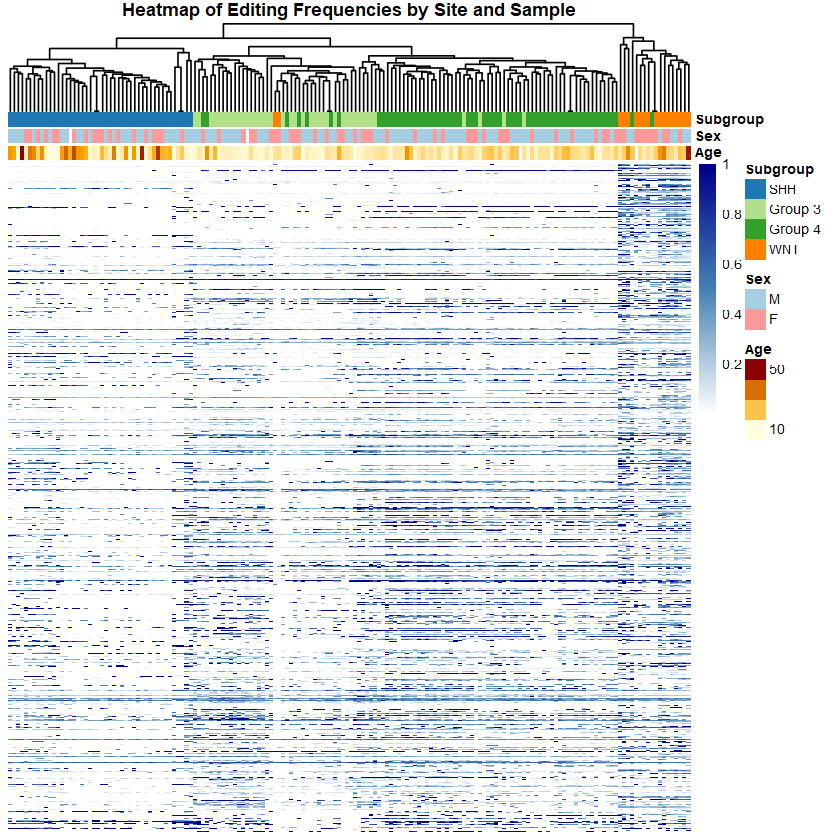

In [13]:
# Make sure you have pheatmap and dplyr loaded
library(pheatmap)
library(dplyr)

# Assume 'df' is your 82264x266 dataframe (sites as rows, samples as columns)
# Assume 'sample_metadata' is your annotation dataframe (sample IDs as row names)

# --- Define colors for annotations (as before) ---
annotation_colors = list(
  Sex = c(M = "#A6CEE3", F = "#FB9A99"),
  Subgroup = c("SHH" = "#1F78B4", "Group 3" = "#B2DF8A", "Group 4" = "#33A02C", "WNT" = "#FF7F00"),
  Age = colorRampPalette(c("lightyellow", "orange", "darkred"))(100)
)

cat("Generating heatmap. Row clustering is disabled due to memory constraints.\n")

# --- Create the heatmap with cluster_rows = FALSE ---
pheatmap(
  mat = df,
  annotation_col = sample_metadata,
  annotation_colors = annotation_colors,
  cluster_rows = FALSE,     # <--- IMPORTANT CHANGE: Disable row clustering
  cluster_cols = TRUE,
  show_rownames = FALSE,    # Keep this as FALSE for readability with many rows
  show_colnames = FALSE,
  main = "Heatmap of Editing Frequencies by Site and Sample",
  fontsize = 8,
  fontsize_col = 7,
  color = colorRampPalette(c("white", "steelblue", "darkblue"))(100),
  treeheight_col = 50,
  # treeheight_row will be ignored when cluster_rows = FALSE
  border_color = "gray80",
  # It's highly recommended to save this directly to a file
  # file = "editing_frequency_heatmap.png",
  # width = 12, height = 15 # Adjust dimensions for your output file
)

cat("Heatmap generation complete.\n")

In [22]:
# Make sure you have pheatmap and dplyr loaded
library(pheatmap)
library(dplyr)

# --- Define colors for annotations (unchanged) ---
annotation_colors = list(
  Sex = c(M = "#A6CEE3", F = "#FB9A99"),
  Subgroup = c("SHH" = "#1F78B4", "Group 3" = "#B2DF8A", "Group 4" = "#33A02C", "WNT" = "#FF7F00"),
  Age = colorRampPalette(c("lightyellow", "orange", "darkred"))(100)
)

cat("Generating heatmap. Row clustering is disabled due to memory constraints.\n")

# --- Anchor the color scale to the real data range ---
# This keeps a couple of extreme values from washing out the rest of the
# heatmap's contrast (a common issue with editing-frequency data, which is
# often heavily right-skewed / zero-inflated).
mat_vals <- as.matrix(df)
mat_vals <- mat_vals[is.finite(mat_vals)]

heat_colors <- colorRampPalette(c("white", "steelblue", "darkblue"))(100)
breaks <- seq(0, quantile(mat_vals, 0.99, na.rm = TRUE), length.out = 101)

# --- Create the heatmap with cluster_rows = FALSE ---
pheatmap(
  mat = df,
  annotation_col = sample_metadata,
  annotation_colors = annotation_colors,
  cluster_rows = FALSE,       # unchanged: row clustering disabled
  cluster_cols = TRUE,
  show_rownames = FALSE,
  show_colnames = FALSE,
  main = "Heatmap of Editing Frequencies by Site and Sample",
  fontsize = 8,
  fontsize_col = 7,
  fontfamily = "sans",        # consistent, print-friendly font
  color = heat_colors,
  breaks = breaks,            # anchors scale to 0-99th percentile of data
  legend_breaks = seq(0, max(breaks), length.out = 5),
  legend_labels = sprintf("%.2f", seq(0, max(breaks), length.out = 5)),
  treeheight_col = 50,
  border_color = NA,          # cleaner at high site/sample counts; avoids
                              # a muddy gray grid overwhelming the color signal
  na_col = "grey90",

  # --- Save directly to file at publication resolution ---
  filename = "H:/Bulk_medulloblastoma_A_to_I_editing_finalized/ICGC_Only_Analysis/Figures/editing_frequency_heatmap.png",  # vector, best for journals
  width = 8,     # inches
  height = 4    # inches
)

cat("Heatmap generation complete. Saved as PDF (vector) to outputs folder.\n")

# --- If a raster format is required (e.g. for a specific journal's submission
# system), swap the filename/args above for:
#   filename = "editing_frequency_heatmap.png",
#   width = 8, height = 10, units = "in", res = 600

Generating heatmap. Row clustering is disabled due to memory constraints.


Heatmap generation complete. Saved as PDF (vector) to outputs folder.


In [26]:
df

,ICGC_MB111_Alt,ICGC_MB134_Alt,ICGC_MB141_Alt,ICGC_MB146_Alt,ICGC_MB18_Alt,ICGC_MB188_Alt,ICGC_MB205_Alt,ICGC_MB235_Alt,ICGC_MB247_Alt,ICGC_MB248_Alt,⋯,ICGC_MB276_Alt,ICGC_MB31_Alt,ICGC_MB46_Alt,ICGC_MB54_Alt,ICGC_MB107_Alt,ICGC_MB112_Alt,ICGC_MB122_Alt,ICGC_MB128_Alt,ICGC_MB140_Alt,ICGC_MB290_Alt
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr6_42889288,0.03963871,0.07434961,0.07686768,0.05060505,0.02067613,0.04436559,0.06472036,0.06913353,0.02682606,0.03167895,⋯,0.03154654,0.00010000,0.03331033,0.03179014,0.00010000,0.04383178,0.00010000,0.00010000,0.05151388,0.03925663
chr2_29030183,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.30779231,0.00010000,0.32540120,0.25010000,0.29367798,0.28450367,0.48158148,0.15654172,0.46163846,0.35907436
chr16_50577404,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.49240769,0.65464545,0.53343333,0.67232222,0.59269259,0.81655570,0.69873014,0.46512058,0.67531368,0.90919091
chr12_65058930,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.54848710,1.00010000,0.47836087,0.67401304,1.00010000,0.54357826,0.74084074,0.59625385,0.54804521,0.77951176
chr16_50576801,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.20418163,0.12748854,0.17293951,0.20657773,0.05541915,0.15364331,0.15241788,0.06676667,0.19403939,0.33562632
chrX_48577960,0.06226216,0.08738653,0.06641763,0.00010000,0.03901772,0.04592210,0.06231548,0.05620561,0.07317172,0.03877069,⋯,0.06662807,0.02804521,0.05399222,0.05138205,0.07164213,0.04228534,0.03635111,0.04488708,0.05844684,0.02513996
chr15_28807046,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000
chr2_177627724,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.34533810,0.37414580,0.30886494,0.28807997,0.28760000,0.32085472,0.24652857,0.21659485,0.19403939,0.29455507
chr16_50580487,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,0.00010000,⋯,0.24252424,0.24752268,0.51734138,0.30256914,0.13228391,0.30402157,0.23135000,0.14970630,0.17767009,0.48524851


In [16]:
getwd()

[1] "E:/MB_Bulk_RNA_seq/Post_Analysis_script"